# 03 · Segmentos, uplift e impacto de negocio

El notebook 02 mostró que el correo de hombre es el mejor en promedio. Aquí respondo tres preguntas más:

1. ¿Hay clientes que respondan mejor al correo de mujer, o a ninguno?
2. ¿Un modelo que elige el correo para cada cliente supera a "mandar el de hombre a todos"?
3. ¿Cuánto dinero representa la decisión?

Solo uso variables medidas **antes** del envío. Segmentar por algo que el correo pudo cambiar (por ejemplo, haber visitado el sitio) rompería la aleatorización.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor

from src.datos import cargar, ORDEN_GRUPOS, COLORES, FIGURAS, POWERBI
from src.estadistica import comparar_medias, comparar_proporciones, ols_robusto, prueba_wald, ajuste_holm, tabla_resultados

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEMILLA = 2024

df = cargar()
df["recency_tercil"] = pd.qcut(df.recency, 3, labels=["1-3 meses", "4-8 meses", "9-12 meses"]).astype(str)
df["history_tercil"] = pd.qcut(df.history, 3, labels=["1) bajo", "2) medio", "3) alto"]).astype(str)

SEGMENTOS = {
    "newbie": "Cliente nuevo",
    "channel": "Canal de compra",
    "zip_code": "Zona",
    "mens": "Compró ropa de hombre",
    "womens": "Compró ropa de mujer",
    "recency_tercil": "Meses desde última compra",
    "history_tercil": "Gasto del último año",
}

## 1. Exploración y confirmación

Con 7 variables y 2 campañas hay 14 posibles interacciones. Si las pruebo todas con α = 0.05, es fácil que alguna salga "significativa" por azar. Para evitarlo:

1. Divido a los clientes al azar en dos mitades (estratificando por grupo).
2. En la **mitad de exploración** pruebo las 14 interacciones y me quedo con las que tengan p < 0.10.
3. En la **mitad de confirmación** pruebo solo esas, con ajuste de Holm.

Cada interacción se prueba con una regresión `spend ~ T + segmento + T × segmento` con errores robustos (HC1) y una prueba de Wald conjunta sobre los términos de interacción.

In [2]:
rng = np.random.default_rng(SEMILLA)
df["mitad"] = ""
for grupo, indices in df.groupby("grupo", observed=True).groups.items():
    idx = np.array(indices)
    rng.shuffle(idx)
    df.loc[idx[: len(idx) // 2], "mitad"] = "exploracion"
    df.loc[idx[len(idx) // 2:], "mitad"] = "confirmacion"

pd.crosstab(df.grupo, df.mitad)

mitad,confirmacion,exploracion
grupo,,
Control,10653,10653
Hombre,10654,10653
Mujer,10694,10693


In [3]:
def p_interaccion(datos, campana, variable):
    """p-valor de la prueba de Wald de que el efecto de `campana` no cambia entre niveles de `variable`."""
    s = datos[datos.grupo.isin([campana, "Control"])]
    T = (s.grupo == campana).astype(float).rename("T")
    D = pd.get_dummies(s[variable].astype(str), prefix=variable, drop_first=True, dtype=float)
    X = pd.concat([pd.Series(1.0, index=s.index, name="const"), T, D, D.mul(T, axis=0).add_prefix("T:")], axis=1)
    tabla = ols_robusto(X, s.spend.to_numpy())
    return prueba_wald(tabla, [c for c in X.columns if c.startswith("T:")])


filas = []
for campana in ["Hombre", "Mujer"]:
    for variable, nombre in SEGMENTOS.items():
        filas.append({
            "campana": campana,
            "segmento": nombre,
            "variable": variable,
            "p_exploracion": p_interaccion(df[df.mitad == "exploracion"], campana, variable),
        })
interacciones = pd.DataFrame(filas)
interacciones["candidata"] = interacciones.p_exploracion < 0.10
interacciones.sort_values("p_exploracion").round(4)

,campana,segmento,variable,p_exploracion,candidata
7,Mujer,Cliente nuevo,newbie,0.0039,True
8,Mujer,Canal de compra,channel,0.0531,True
0,Hombre,Cliente nuevo,newbie,0.2524,False
9,Mujer,Zona,zip_code,0.2719,False
2,Hombre,Zona,zip_code,0.3489,False
6,Hombre,Gasto del último año,history_tercil,0.4023,False
5,Hombre,Meses desde última compra,recency_tercil,0.5462,False
13,Mujer,Gasto del último año,history_tercil,0.6760,False
4,Hombre,Compró ropa de mujer,womens,0.6989,False
11,Mujer,Compró ropa de mujer,womens,0.7111,False


In [4]:
candidatas = interacciones[interacciones.candidata].copy()
candidatas["p_confirmacion"] = [
    p_interaccion(df[df.mitad == "confirmacion"], r.campana, r.variable) for r in candidatas.itertuples()
]
candidatas["p_holm"] = ajuste_holm(candidatas.p_confirmacion)
candidatas["confirmada"] = np.where(candidatas.p_holm < 0.05, "Sí", "No")
candidatas[["campana", "segmento", "p_exploracion", "p_confirmacion", "p_holm", "confirmada"]].round(4)

,campana,segmento,p_exploracion,p_confirmacion,p_holm,confirmada
7,Mujer,Cliente nuevo,0.0039,0.7204,1.0,No
8,Mujer,Canal de compra,0.0531,0.9423,1.0,No


Dos interacciones parecían prometedoras en la exploración, ambas del correo de mujer: por cliente nuevo y por canal de compra. **Ninguna se repite en la mitad de confirmación.** Si hubiera analizado los 64,000 clientes de una vez y reportado la mejor interacción, habría presentado un hallazgo que muy probablemente es ruido.

## 2. Efecto de cada campaña por segmento

Aunque las diferencias entre segmentos no se confirmaron, la tabla por segmento es útil para ver si en algún grupo conviene otra campaña. Uso todos los datos y la trato como **exploratoria**.

In [5]:
filas = []
for variable, nombre in SEGMENTOS.items():
    for nivel, sub in df.groupby(variable):
        for campana in ["Hombre", "Mujer"]:
            r = comparar_medias(sub.loc[sub.grupo == campana, "spend"], sub.loc[sub.grupo == "Control", "spend"],
                                "spend", f"{campana} vs Control")
            filas.append({
                "segmento": nombre,
                "nivel": str(nivel),
                "campana": campana,
                "clientes_segmento": len(sub),
                "ingreso_control": r.control,
                "ingreso_campana": r.tratamiento,
                "efecto": r.diferencia,
                "ic_inf": r.ic_inf,
                "ic_sup": r.ic_sup,
            })
por_segmento = pd.DataFrame(filas)
por_segmento.pivot_table(index=["segmento", "nivel"], columns="campana", values="efecto").round(3)

campana                                 Hombre  Mujer
segmento                  nivel                      
Canal de compra           Multichannel   1.209  1.158
                          Phone          0.564  0.232
                          Web            0.850  0.416
Cliente nuevo             0              0.578  0.114
                          1              0.960  0.732
Compró ropa de hombre     0              0.616  0.632
                          1              0.897  0.256
Compró ropa de mujer      0              0.683  0.278
                          1              0.841  0.544
Gasto del último año      1) bajo        0.556  0.648
                          2) medio       0.711  0.267
                          3) alto        1.046  0.356
Meses desde última compra 1-3 meses      1.048  0.359
                          4-8 meses      0.462  0.468
                          9-12 meses     0.793  0.453
Zona                      Rural          0.756  0.515
                          Surburban      0.804  0.177
                          Urban          0.737  0.669

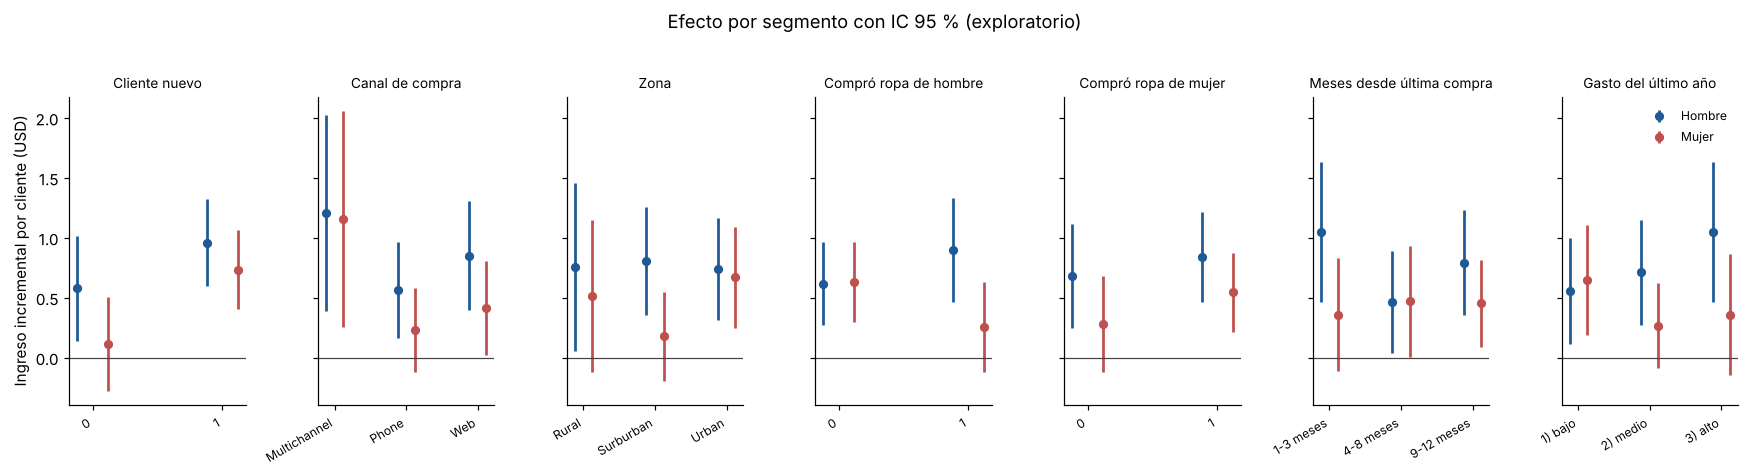

In [6]:
fig, axes = plt.subplots(1, len(SEGMENTOS), figsize=(16, 4.2), sharey=True)
for ax, (variable, nombre) in zip(axes, SEGMENTOS.items()):
    sub = por_segmento[por_segmento.segmento == nombre]
    niveles = sub.nivel.unique()
    x = np.arange(len(niveles))
    for desplazamiento, campana in [(-0.12, "Hombre"), (0.12, "Mujer")]:
        s = sub[sub.campana == campana].set_index("nivel").loc[niveles]
        ax.errorbar(x + desplazamiento, s.efecto, yerr=[s.efecto - s.ic_inf, s.ic_sup - s.efecto],
                    fmt="o", color=COLORES[campana], ms=5, capsize=0, elinewidth=1.8, label=campana)
    ax.axhline(0, color="#444", lw=0.8)
    ax.set_xticks(x, niveles, rotation=30, ha="right", fontsize=8)
    ax.set_title(nombre, fontsize=9)
axes[0].set_ylabel("Ingreso incremental por cliente (USD)")
axes[-1].legend(frameon=False, fontsize=8)
fig.suptitle("Efecto por segmento con IC 95 % (exploratorio)", y=1.02)
fig.tight_layout()
fig.savefig(FIGURAS / "03_efecto_por_segmento.png", dpi=150, bbox_inches="tight")

In [7]:
mejor = por_segmento.pivot_table(index=["segmento", "nivel"], columns="campana", values="efecto")
print(f"Segmentos donde el correo de mujer tiene mayor efecto estimado que el de hombre: "
      f"{(mejor.Mujer > mejor.Hombre).sum()} de {len(mejor)}")
print(mejor[mejor.Mujer > mejor.Hombre].round(3))

Segmentos donde el correo de mujer tiene mayor efecto estimado que el de hombre: 3 de 18
campana                              Hombre  Mujer
segmento                  nivel                   
Compró ropa de hombre     0           0.616  0.632
Gasto del último año      1) bajo     0.556  0.648
Meses desde última compra 4-8 meses   0.462  0.468


El correo de hombre tiene efecto estimado positivo en todos los segmentos. Solo en 3 de 18 segmentos el de mujer queda arriba, y por menos de 0.10 USD, una diferencia mínima frente a intervalos muy anchos. No hay ningún segmento con evidencia de que convenga no mandar correo.

## 3. Modelo de uplift: ¿elegir el correo para cada cliente?

Una regla por segmento es limitada. Un modelo puede combinar todas las variables y elegir, para cada cliente, el correo con mayor ingreso esperado. Uso un **T-learner**: un modelo por grupo que predice el resultado con las variables previas al envío; para cada cliente se compara lo que predicen los tres modelos.

**Separación de datos** (para no evaluar con datos que el modelo ya vio):

| Conjunto | Uso | Proporción |
|---|---|---|
| Entrenamiento | Ajustar los modelos | 49 % |
| Validación | Elegir entre variantes de modelo | 21 % |
| Prueba | Evaluar una sola vez la regla final | 30 % |

**Cómo se evalúa una regla:** como la asignación fue aleatoria, el ingreso esperado de una regla se estima con los clientes cuyo grupo asignado coincide con lo que la regla habría elegido, ponderados por la inversa de la probabilidad de asignación (IPW). Así se comparan reglas sin suponer que el modelo acierta.

In [8]:
X = pd.get_dummies(df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]], dtype=float)
grupo = df.grupo.astype(str)

# Fuga de información: las variables solo describen al cliente antes del envío y cada cliente está en un
# solo conjunto, así que entrenamiento, validación y prueba no comparten información.
idx_entr_total, idx_prueba = train_test_split(df.index, test_size=0.30, random_state=SEMILLA, stratify=grupo)
idx_entr, idx_valid = train_test_split(idx_entr_total, test_size=0.30, random_state=SEMILLA, stratify=grupo[idx_entr_total])
prob_asignacion = grupo.value_counts(normalize=True).to_dict()
print({k: f"{v:.4f}" for k, v in prob_asignacion.items()})
print(f"Entrenamiento: {len(idx_entr):,} · Validación: {len(idx_valid):,} · Prueba: {len(idx_prueba):,}")

{'Mujer': '0.3342', 'Hombre': '0.3329', 'Control': '0.3329'}
Entrenamiento: 31,360 · Validación: 13,440 · Prueba: 19,200


In [9]:
VARIANTES = {
    "Logística sobre conversión": ("clasificacion", lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))),
    "Gradient boosting sobre conversión": ("clasificacion", lambda: HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=200, random_state=0)),
    "Ridge sobre gasto": ("regresion", lambda: make_pipeline(StandardScaler(), Ridge(alpha=100))),
    "Gradient boosting sobre gasto": ("regresion", lambda: HistGradientBoostingRegressor(
        max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=200, random_state=0)),
}


def entrenar(tipo, constructor, indices):
    objetivo = "conversion" if tipo == "clasificacion" else "spend"
    return {g: constructor().fit(X.loc[i], df.loc[i, objetivo])
            for g in ORDEN_GRUPOS for i in [indices[grupo[indices] == g]]}


def predecir(modelos, tipo, indices):
    if tipo == "clasificacion":
        return pd.DataFrame({g: m.predict_proba(X.loc[indices])[:, 1] for g, m in modelos.items()}, index=indices)
    return pd.DataFrame({g: m.predict(X.loc[indices]) for g, m in modelos.items()}, index=indices)


def contribuciones_ipw(indices, politica):
    """Aporte de cada cliente al ingreso esperado de la regla (su media es el estimador IPW)."""
    g = grupo[indices].to_numpy()
    peso = np.array([1 / prob_asignacion[x] for x in g])
    return df.loc[indices, "spend"].to_numpy() * peso * (g == np.asarray(politica))


def valor_regla(indices, politica):
    v = contribuciones_ipw(indices, politica)
    return v.mean(), v.std(ddof=1) / np.sqrt(len(v))


filas = []
for nombre, (tipo, constructor) in VARIANTES.items():
    modelos = entrenar(tipo, constructor, idx_entr)
    politica = predecir(modelos, tipo, idx_valid).idxmax(axis=1).to_numpy()
    valor, ee = valor_regla(idx_valid, politica)
    filas.append({"variante": nombre, "ingreso_esperado": valor, "error_estandar": ee,
                  "pct_hombre": (politica == "Hombre").mean(), "pct_mujer": (politica == "Mujer").mean(),
                  "pct_sin_correo": (politica == "Control").mean()})
for g in ORDEN_GRUPOS:
    valor, ee = valor_regla(idx_valid, [g] * len(idx_valid))
    filas.append({"variante": f"Regla simple: todos {g}", "ingreso_esperado": valor, "error_estandar": ee})
validacion = pd.DataFrame(filas).set_index("variante")
validacion.round(3)

,ingreso_esperado,error_estandar,pct_hombre,pct_mujer,pct_sin_correo
variante,,,,,
Logística sobre conversión,1.665,0.303,0.915,0.070,0.015
Gradient boosting sobre conversión,1.152,0.242,0.797,0.120,0.083
Ridge sobre gasto,1.385,0.266,0.771,0.157,0.073
Gradient boosting sobre gasto,1.503,0.275,0.675,0.292,0.033
Regla simple: todos Control,0.578,0.151,NaN,NaN,NaN
Regla simple: todos Hombre,1.465,0.278,NaN,NaN,NaN
Regla simple: todos Mujer,0.875,0.200,NaN,NaN,NaN


En validación, la regresión logística sobre conversión obtiene el mayor ingreso esperado entre los modelos, así que es la variante que llevo a prueba. Ojo con el error estándar: va de 0.24 a 0.30 USD, del mismo tamaño que las diferencias entre variantes. Elegir "la mejor" aquí ya es casi elegir por azar, y por eso la evaluación en prueba es la que cuenta.

### Evaluación final en el conjunto de prueba

Reentreno la variante elegida con entrenamiento + validación y la evalúo una sola vez en prueba. La comparación clave es contra la mejor regla simple: mandar el correo de hombre a todos. Para esa diferencia uso los mismos clientes en ambas reglas (comparación pareada).

In [10]:
tipo, constructor = VARIANTES["Logística sobre conversión"]
modelos_finales = entrenar(tipo, constructor, idx_entr_total)
politica_modelo = predecir(modelos_finales, tipo, idx_prueba).idxmax(axis=1).to_numpy()

reglas = {
    "Sin correo": ["Control"] * len(idx_prueba),
    "Todos: correo de mujer": ["Mujer"] * len(idx_prueba),
    "Todos: correo de hombre": ["Hombre"] * len(idx_prueba),
    "Modelo de uplift": politica_modelo,
}
filas = []
for nombre, politica in reglas.items():
    valor, ee = valor_regla(idx_prueba, politica)
    filas.append({"regla": nombre, "ingreso_por_cliente": valor, "ic_inf": valor - 1.96 * ee, "ic_sup": valor + 1.96 * ee})
valor_reglas = pd.DataFrame(filas).set_index("regla")
print("Asignación del modelo en prueba:", pd.Series(politica_modelo).value_counts(normalize=True).round(3).to_dict())
valor_reglas.round(3)

Asignación del modelo en prueba: {'Hombre': 0.864, 'Mujer': 0.133, 'Control': 0.003}


,ingreso_por_cliente,ic_inf,ic_sup
regla,,,
Sin correo,0.622,0.337,0.906
Todos: correo de mujer,1.302,0.887,1.717
Todos: correo de hombre,1.291,0.868,1.714
Modelo de uplift,1.138,0.768,1.508


In [11]:
dif = contribuciones_ipw(idx_prueba, politica_modelo) - contribuciones_ipw(idx_prueba, reglas["Todos: correo de hombre"])
ee_dif = dif.std(ddof=1) / np.sqrt(len(dif))
print(f"Modelo de uplift − todos correo de hombre: {dif.mean():+.3f} USD por cliente "
      f"(IC 95 %: {dif.mean() - 1.96 * ee_dif:+.3f} a {dif.mean() + 1.96 * ee_dif:+.3f})")

Modelo de uplift − todos correo de hombre: -0.153 USD por cliente (IC 95 %: -0.406 a +0.100)


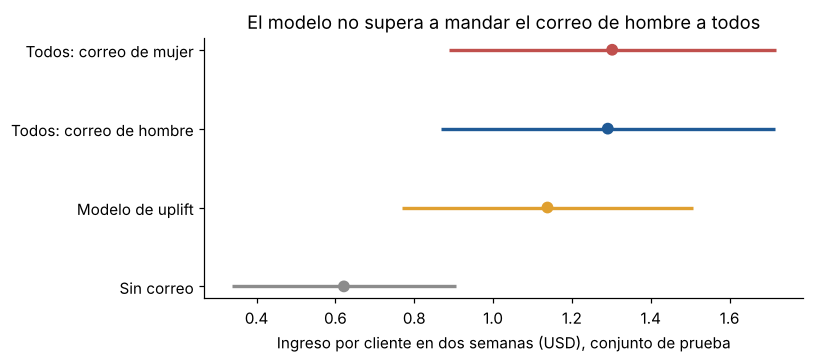

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
orden = valor_reglas.sort_values("ingreso_por_cliente")
colores = {"Sin correo": COLORES["Control"], "Todos: correo de mujer": COLORES["Mujer"],
           "Todos: correo de hombre": COLORES["Hombre"], "Modelo de uplift": "#E0A030"}
y = np.arange(len(orden))
ax.errorbar(orden.ingreso_por_cliente, y, xerr=[orden.ingreso_por_cliente - orden.ic_inf, orden.ic_sup - orden.ingreso_por_cliente],
            fmt="none", ecolor=[colores[r] for r in orden.index], elinewidth=2.2)
ax.scatter(orden.ingreso_por_cliente, y, color=[colores[r] for r in orden.index], zorder=3, s=45)
ax.set_yticks(y, orden.index)
ax.set_xlabel("Ingreso por cliente en dos semanas (USD), conjunto de prueba")
ax.set_title("El modelo no supera a mandar el correo de hombre a todos")
fig.tight_layout()
fig.savefig(FIGURAS / "03_valor_reglas.png", dpi=150, bbox_inches="tight")

El modelo de uplift no mejora a la regla simple: queda 0.15 USD por cliente abajo y el intervalo de la diferencia incluye el cero. Con ~580 compradores en todo el experimento, no hay suficiente señal para personalizar.

Un detalle: en este 30 % de prueba, "todos con correo de mujer" y "todos con correo de hombre" quedan prácticamente empatados, aunque con los 64,000 clientes el de hombre gana con claridad (notebook 02). Es el mismo problema de poder: el conjunto de prueba tiene un tercio de los datos y sirve para evaluar el modelo, no para elegir entre campañas. Esa decisión se toma con la muestra completa.

**La regla recomendada es la simple: mandar el correo de hombre a todos.** Es además más fácil de operar y de explicar.

## 4. Impacto de negocio

Uso el efecto estimado con los 64,000 clientes (notebook 02), que es más preciso que el del conjunto de prueba.

In [13]:
efectos = []
for campana in ["Hombre", "Mujer"]:
    efectos.append(comparar_medias(df.loc[df.grupo == campana, "spend"], df.loc[df.grupo == "Control", "spend"],
                                   "spend", f"{campana} vs Control"))
efectos = tabla_resultados(efectos)

impacto = pd.DataFrame({
    "campana": ["Hombre", "Mujer"],
    "ingreso_incremental_por_1000_correos": efectos.diferencia.to_numpy() * 1000,
    "ic_inf": efectos.ic_inf.to_numpy() * 1000,
    "ic_sup": efectos.ic_sup.to_numpy() * 1000,
}).set_index("campana")
impacto.round(0)

,ingreso_incremental_por_1000_correos,ic_inf,ic_sup
campana,,,
Hombre,770.0,485.0,1055.0
Mujer,424.0,169.0,680.0


Cada 1,000 correos de hombre generan unos 770 USD de ingreso adicional en dos semanas (IC 95 %: 485 a 1,055).

El dataset no trae costos ni márgenes, así que lo que sigue son **supuestos** para mostrar cómo decidir:

- **Margen bruto:** escenarios de 30 %, 40 % y 50 % sobre el ingreso.
- **Costo por correo:** el costo de enviar correo masivo suele ser de centavos o fracciones de centavo; tomo 0.01 USD como referencia.

La pregunta es cuál es el costo máximo por correo con el que la campaña todavía deja ganancia, usando el **límite inferior** del intervalo para ser conservador.

In [14]:
escenarios = []
for margen in [0.30, 0.40, 0.50]:
    for campana in ["Hombre", "Mujer"]:
        fila = efectos[efectos.comparacion == f"{campana} vs Control"].iloc[0]
        escenarios.append({
            "margen": f"{margen:.0%}",
            "campana": campana,
            "utilidad_por_correo": fila.diferencia * margen,
            "costo_maximo_por_correo": fila.ic_inf * margen,
            "utilidad_neta_por_1000_con_costo_0.01": (fila.diferencia * margen - 0.01) * 1000,
        })
escenarios = pd.DataFrame(escenarios).set_index(["margen", "campana"])
escenarios.round(3)

utilidad_por_correo  ...  utilidad_neta_por_1000_con_costo_0.01
margen campana                       ...                                       
30%    Hombre                 0.231  ...                                220.948
       Mujer                  0.127  ...                                117.324
40%    Hombre                 0.308  ...                                297.931
       Mujer                  0.170  ...                                159.765
50%    Hombre                 0.385  ...                                374.914
       Mujer                  0.212  ...                                202.206

[6 rows x 3 columns]

Incluso en el escenario más conservador (margen de 30 % y límite inferior del intervalo), el correo de hombre deja ganancia mientras cueste menos de ~0.15 USD por envío, muy por encima del costo típico de un correo masivo. La decisión de mandar es robusta a los supuestos; lo que realmente importa es cuál correo se manda.

**Escala:** en una lista como la de este experimento (64,000 clientes), mandar el correo de hombre a todos en vez de no mandar nada generaría unos 49 mil USD de ingreso adicional en dos semanas, contra unos 27 mil USD con el correo de mujer.

In [15]:
lista = len(df)
for campana in ["Hombre", "Mujer"]:
    fila = efectos[efectos.comparacion == f"{campana} vs Control"].iloc[0]
    print(f"{campana}: {fila.diferencia * lista:,.0f} USD (IC 95 %: {fila.ic_inf * lista:,.0f} a {fila.ic_sup * lista:,.0f})")

Hombre: 49,269 USD (IC 95 %: 31,050 a 67,488)
Mujer: 27,162 USD (IC 95 %: 10,814 a 43,511)


## 5. Datos para el reporte de Power BI

Exporto las tablas que alimentan el reporte de decisión. Las instrucciones para armarlo están en [`reports/README.md`](../reports/README.md).

In [16]:
resumen = df.groupby("grupo", observed=True).agg(
    clientes=("spend", "size"), visitas=("visit", "sum"), compradores=("conversion", "sum"),
    ingreso_total=("spend", "sum"), tasa_visita=("visit", "mean"), tasa_conversion=("conversion", "mean"),
    ingreso_por_cliente=("spend", "mean"),
).reset_index()
resumen.to_csv(POWERBI / "resumen_grupos.csv", index=False)

principales = []
for metrica, prueba in [("visit", comparar_proporciones), ("conversion", comparar_proporciones), ("spend", comparar_medias)]:
    for a, b in [("Hombre", "Control"), ("Mujer", "Control"), ("Hombre", "Mujer")]:
        principales.append(prueba(df.loc[df.grupo == a, metrica], df.loc[df.grupo == b, metrica], metrica, f"{a} vs {b}"))
tabla_resultados(principales).to_csv(POWERBI / "efectos_principales.csv", index=False)

por_segmento.to_csv(POWERBI / "efectos_por_segmento.csv", index=False)
valor_reglas.reset_index().to_csv(POWERBI / "valor_reglas.csv", index=False)
escenarios.reset_index().to_csv(POWERBI / "escenarios_impacto.csv", index=False)

sorted(p.name for p in POWERBI.glob("*.csv"))

['efectos_por_segmento.csv', 'efectos_principales.csv', 'escenarios_impacto.csv', 'resumen_grupos.csv', 'valor_reglas.csv']

## Conclusión

| Pregunta | Respuesta |
|---|---|
| ¿Hay segmentos que respondan distinto? | Dos interacciones parecían prometedoras, pero ninguna se confirmó en la mitad independiente |
| ¿Conviene otra campaña en algún segmento? | No: el correo de hombre tiene efecto estimado positivo en todos y gana en 15 de 18 segmentos |
| ¿Un modelo de uplift mejora la decisión? | No: en prueba queda 0.15 USD por cliente abajo de la regla simple (IC 95 %: −0.41 a +0.10) |
| ¿Cuánto vale la decisión? | ~770 USD por cada 1,000 correos (IC 95 %: 485 a 1,055) |

**Recomendación:** mandar el correo de hombre a toda la base. Como siguiente experimento, probar una versión mejorada de ese correo contra la actual, con un grupo de control sin correo para seguir midiendo el efecto incremental.